# 04. Quantitative Performance and Risk Analytics Engine
Mathematical computation of CAGR, annualized volatility, Sharpe, Sortino, Beta, Alpha, and Maximum Drawdown using 252 trading-day convention.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(str(Path('..').resolve()))
from scripts.compute_metrics import calculate_scheme_metrics

proc_dir = Path('../data/processed')
df_nav = pd.read_csv(proc_dir / 'fact_nav.csv')
df_perf = pd.read_csv(proc_dir / 'fact_performance.csv')
df_bench = pd.read_csv(proc_dir / '10_benchmark_indices.csv')


## Benchmark Alignment and Risk-Adjusted Analytics Engine
Iterating across all 40 schemes to compute quantitative metrics using trading-day annualization.


In [2]:
nifty_bench = df_bench[df_bench['index_name'] == 'NIFTY 50'].set_index('date')['close_value']

results = []
for amfi, group in df_nav.groupby('amfi_code'):
    s_nav = group.set_index('nav_date')['nav']
    m = calculate_scheme_metrics(s_nav, nifty_bench)
    m['amfi_code'] = amfi
    results.append(m)

df_computed = pd.DataFrame(results)
merged_analysis = pd.merge(df_perf[['amfi_code', 'scheme_name', 'category', 'fund_house']], df_computed, on='amfi_code')
merged_analysis.sort_values(by='sharpe_ratio', ascending=False).head(10)


,amfi_code,scheme_name,category,fund_house,n_trading_days,cagr,annualized_volatility,sharpe_ratio,sortino_ratio,max_drawdown,beta,alpha
34,148567,Mirae Asset Large Cap Fund - Regular - Growth,Large Cap,Mirae Asset MF,1608,0.204482,0.120250,1.201516,1.039452,-0.112657,1.0,0.0
22,120843,Kotak Flexicap Fund - Regular - Growth,Flexi Cap,Kotak Mahindra MF,1608,0.204060,0.134543,1.070731,0.974965,-0.129740,1.0,0.0
36,148569,Mirae Asset Tax Saver Fund - Regular - Growth,ELSS,Mirae Asset MF,1608,0.210660,0.149645,1.006782,0.908957,-0.163967,1.0,0.0
0,119551,SBI Bluechip Fund - Regular Plan - Growth,Large Cap,SBI Mutual Fund,1608,0.171499,0.116365,0.958179,0.850787,-0.150124,1.0,0.0
12,120505,ICICI Pru Midcap Fund - Regular - Growth,Mid Cap,ICICI Prudential MF,1608,0.216208,0.163311,0.956506,0.853057,-0.181885,1.0,0.0
38,149323,DSP Midcap Fund - Regular - Growth,Mid Cap,DSP Mutual Fund,1608,0.195635,0.150229,0.902853,0.777080,-0.172481,1.0,0.0
7,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Mid Cap,HDFC Mutual Fund,1608,0.199081,0.160291,0.867678,0.763251,-0.162172,1.0,0.0
15,118632,Nippon India Large Cap Fund - Regular - Growth,Large Cap,Nippon India MF,1608,0.160205,0.119781,0.836568,0.735510,-0.174141,1.0,0.0
28,101206,ABSL Frontline Equity Fund - Regular - Growth,Large Cap,Aditya Birla Sun Life MF,1608,0.156906,0.123321,0.785805,0.701865,-0.112916,1.0,0.0
11,120504,ICICI Pru Bluechip Fund - Direct - Growth,Large Cap,ICICI Prudential MF,1608,0.155335,0.121592,0.784061,0.683512,-0.125883,1.0,0.0


## Cumulative Underwater Drawdown Analysis
Visualizing historical drawdowns for top three active equity schemes across market regimes.


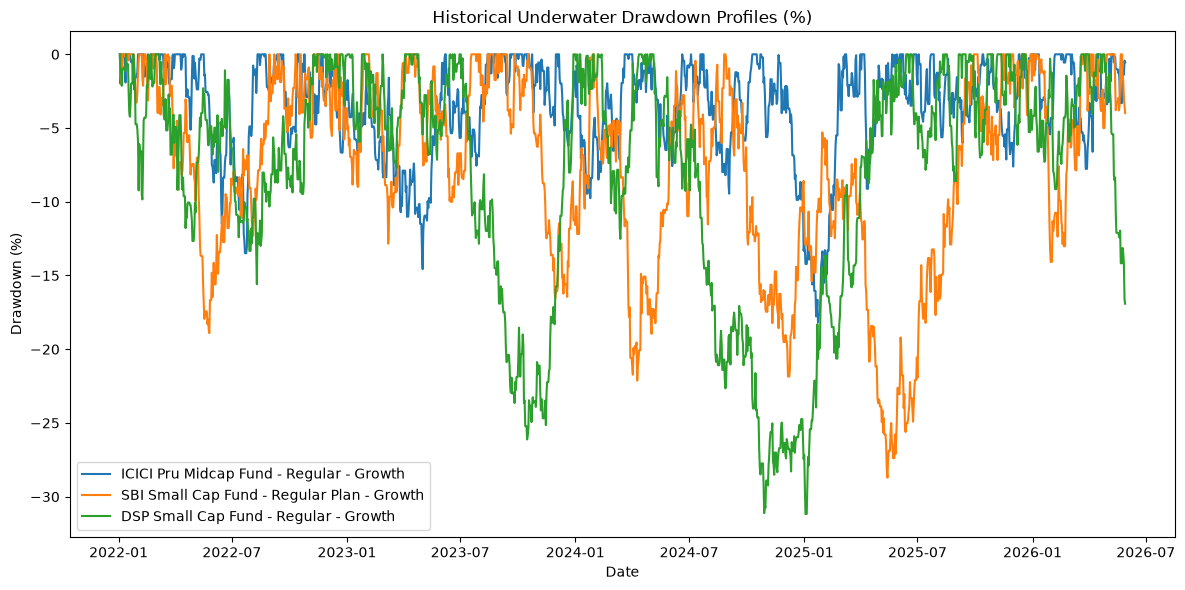

In [3]:
plt.figure(figsize=(12, 6))
top_3_amfi = merged_analysis.sort_values(by='cagr', ascending=False)['amfi_code'].head(3).tolist()

for code in top_3_amfi:
    s_nav = df_nav[df_nav['amfi_code'] == code].set_index('nav_date')['nav']
    peak = s_nav.cummax()
    dd = (s_nav - peak) / peak
    name = df_perf[df_perf['amfi_code'] == code]['scheme_name'].iloc[0]
    plt.plot(pd.to_datetime(s_nav.index), dd * 100, label=name, linewidth=1.5)

plt.title('Historical Underwater Drawdown Profiles (%)')
plt.xlabel('Date')
plt.ylabel('Drawdown (%)')
plt.legend()
plt.tight_layout()
plt.show()


## Quantitative Risk Summary Matrix by Mutual Fund Category
Evaluating category-level mean Sharpe ratios, downside deviations, and market Beta sensitivity.


In [4]:
merged_analysis.groupby('category').agg({
    'cagr': lambda x: f'{x.mean()*100:.2f}%',
    'annualized_volatility': lambda x: f'{x.mean()*100:.2f}%',
    'sharpe_ratio': 'mean',
    'sortino_ratio': 'mean',
    'beta': 'mean',
    'max_drawdown': lambda x: f'{x.mean()*100:.2f}%'
})


,cagr,annualized_volatility,sharpe_ratio,sortino_ratio,beta,max_drawdown
category,,,,,,
ELSS,21.07%,14.96%,1.006782,0.908957,1.0,-16.40%
Flexi Cap,15.87%,13.39%,0.735230,0.665913,1.0,-17.26%
Gilt,3.83%,3.37%,-0.644536,-0.570543,1.0,-6.32%
Index,12.24%,10.86%,0.574502,0.507046,1.0,-10.86%
Index/ETF,10.75%,10.99%,0.432169,0.382085,1.0,-11.65%
Large & Mid Cap,15.03%,13.06%,0.691531,0.609859,1.0,-15.27%
Large Cap,11.81%,11.96%,0.485453,0.427370,1.0,-15.74%
Liquid,4.70%,0.46%,-2.801351,-3.533453,1.0,-0.13%
Mid Cap,13.26%,15.68%,0.453422,0.402599,1.0,-20.82%
